In [2]:
import pandas as pd

In [3]:
import numpy as np

In [4]:
import matplotlib.pyplot as plt

In [10]:
import seaborn  as sns

In [6]:
# Import excel file to read data

In [11]:
df=pd.read_excel(r"C:\Users\Yash\Desktop\JupterExcel.xlsx")
print(df)

        id  Gender Customer Type     Class  Flight Distance  Departure Delay  \
0    70204    Male      Disloyal       Eco             2277               40   
1    70246    Male      Disloyal  Business              480               90   
2    70129    Male      Disloyal       Eco             2113                0   
3    70128  Female         Loyal  Business             2583               90   
4    70028  Female         Loyal       Eco              358                0   
..     ...     ...           ...       ...              ...              ...   
251  70083    Male         Loyal  Business              869               90   
252  70176    Male         Loyal  Eco Plus             2626               90   
253  70067  Female      Disloyal       Eco             2365               15   
254  70127    Male         Loyal  Business             1863                5   
255  70035    Male      Disloyal  Eco Plus             2188                0   

     Arrival Delay  Seat Comfort  Infli

In [12]:
#Library Functions
%matplotlib inline
sns.set_theme(style="whitegrid")

In [13]:
# Use to find Duplicate and Missing Values and also sum of duplicates and Missing values

In [14]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (256, 11)

Column Names:
['id', 'Gender', 'Customer Type', 'Class', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Seat Comfort', 'Inflight Service', 'Cleanliness', 'Satisfaction']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 256 entries, 0 to 255
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                256 non-null    int64  
 1   Gender            256 non-null    str    
 2   Customer Type     256 non-null    str    
 3   Class             256 non-null    str    
 4   Flight Distance   256 non-null    int64  
 5   Departure Delay   256 non-null    int64  
 6   Arrival Delay     246 non-null    float64
 7   Seat Comfort      256 non-null    int64  
 8   Inflight Service  256 non-null    int64  
 9   Cleanliness       256 non-null    int64  
 10  Satisfaction      256 non-null    str    
dtypes: float64(1), int64(6), str(4)
memory usage: 30.5 KB

Missing 

In [15]:
#1)Fills Missing Vales and 2)Remove Duplicates,3)Change service rating good,average,poor and 4)create flight distance category

In [16]:
# Create a copy of the original data
clean_df = df.copy()

# Fill blank Arrival Delay with Departure Delay
clean_df["Arrival Delay"] = clean_df["Arrival Delay"].fillna(
    clean_df["Departure Delay"]
)

# Convert ratings into labels
def rating_label(rating):
    if rating in [1, 2]:
        return "Poor"
    elif rating == 3:
        return "Average"
    elif rating in [4, 5]:
        return "Good"
    else:
        return np.nan

rating_columns = ["Seat Comfort", "Inflight Service", "Cleanliness"]

for col in rating_columns:
    clean_df[col] = clean_df[col].apply(rating_label)

#Remove duplicate rows
clean_df = clean_df.drop_duplicates().copy()

# Add Distance Band using NumPy
conditions = [
    clean_df["Flight Distance"] <= 500,
    clean_df["Flight Distance"].between(501, 1500),
    clean_df["Flight Distance"] > 1500
]
labels = ["Short", "Medium", "Long"]
clean_df["Distance Band"] = np.select(
    conditions, labels, default="Unknown"
)
clean_df.head()

,id,Gender,Customer Type,Class,Flight Distance,Departure Delay,Arrival Delay,Seat Comfort,Inflight Service,Cleanliness,Satisfaction,Distance Band
0,70204,Male,Disloyal,Eco,2277,40,50.0,Poor,Good,Good,Neutral or Dissatisfied,Long
1,70246,Male,Disloyal,Business,480,90,90.0,Poor,Average,Poor,Neutral or Dissatisfied,Short
2,70129,Male,Disloyal,Eco,2113,0,9.0,Good,Poor,Good,Satisfied,Long
3,70128,Female,Loyal,Business,2583,90,90.0,Poor,Good,Good,Satisfied,Long
4,70028,Female,Loyal,Eco,358,0,0.0,Poor,Good,Poor,Neutral or Dissatisfied,Short


In [17]:
#Check  or Verify that the cleaning worked correctly before making your dashboard.

In [18]:
print("Original Rows:", len(df))
print("Cleaned Rows:", len(clean_df))

print("\nMissing Values:")
print(clean_df.isnull().sum())

print("\nDuplicate Rows:", clean_df.duplicated().sum())

print("\nDistance Band Counts:")
print(clean_df["Distance Band"].value_counts())

Original Rows: 256
Cleaned Rows: 250

Missing Values:
id                  0
Gender              0
Customer Type       0
Class               0
Flight Distance     0
Departure Delay     0
Arrival Delay       0
Seat Comfort        0
Inflight Service    0
Cleanliness         0
Satisfaction        0
Distance Band       0
dtype: int64

Duplicate Rows: 0

Distance Band Counts:
Distance Band
Long      146
Medium     74
Short      30
Name: count, dtype: int64


In [19]:
# creates a CSV file that you can also use in Excel and Power BI

In [20]:
clean_df.to_csv(r"C:\Users\Yash\Desktop\Airline_Cleaned_Data.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [21]:
#Calculate dashboard Key performance indicator
#It is a measurable value used to check how well a person, business, or project is achieving its goals.

In [22]:
total_passengers = len(clean_df)
satisfied_passengers = (
    clean_df["Satisfaction"] == "Satisfied"
).sum()
satisfaction_rate = (
    satisfied_passengers / total_passengers
) * 100

average_departure_delay = clean_df["Departure Delay"].mean()
print("Total Passengers:", total_passengers)
print("Satisfied Passengers:", satisfied_passengers)
print("Satisfaction Rate:", round(satisfaction_rate, 2), "%")
print("Average Departure Delay:", round(average_departure_delay, 2), "minutes")

Total Passengers: 250
Satisfied Passengers: 126
Satisfaction Rate: 50.4 %
Average Departure Delay: 26.32 minutes


In [23]:
#Create a Dashboards Charts or graphs for Airplane Passenger Satisfaction

In [24]:
#Passenger Satisfaction

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_style("white")

satisfaction_colors = {
    "Satisfied": "#3498DB",
    "Neutral or Dissatisfied": "#F39C12"
}

rating_colors = {
    "Poor": "#F39C12",
    "Average": "#95A5A6",
    "Good": "#3498DB"
}

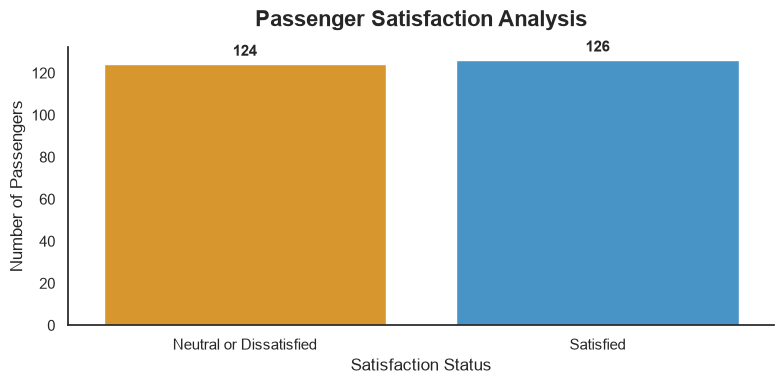

In [27]:
plt.figure(figsize=(8, 4))

ax = sns.countplot(
    data=clean_df,
    x="Satisfaction",
    hue="Satisfaction",
    hue_order=["Neutral or Dissatisfied", "Satisfied"],
    palette=satisfaction_colors,
    legend=False
)

plt.title("Passenger Satisfaction Analysis",
          fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Satisfaction Status", fontsize=12)
plt.ylabel("Number of Passengers", fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=4, fontsize=11,
                 fontweight="bold")

plt.grid(False)
sns.despine()
plt.tight_layout()
plt.show()

In [22]:
#Satisfaction by Travel Class

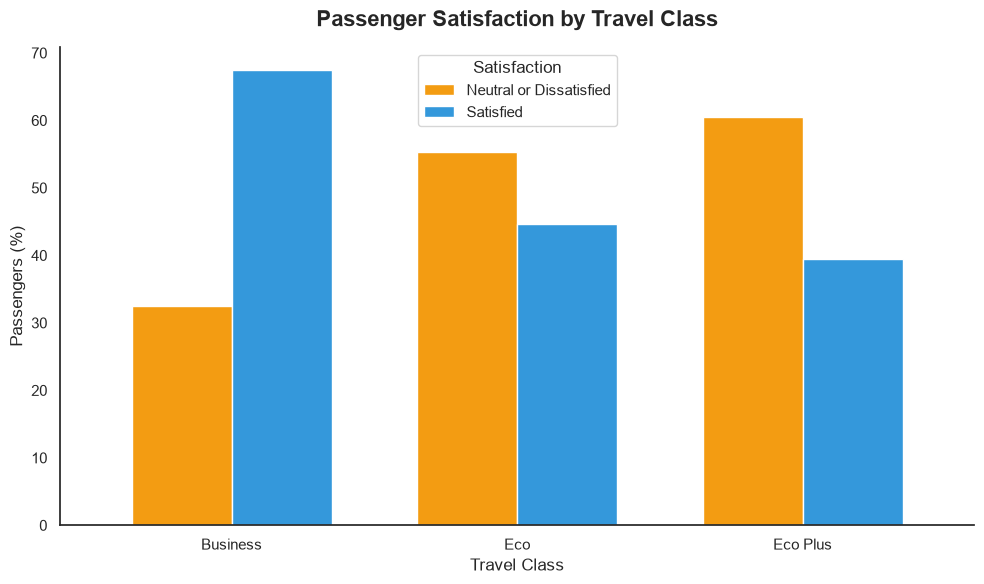

In [30]:
class_satisfaction = pd.crosstab(
    clean_df["Class"],
    clean_df["Satisfaction"],
    normalize="index"
) * 100

class_satisfaction = class_satisfaction.reindex(
    columns=["Neutral or Dissatisfied", "Satisfied"],
    fill_value=0
)


x = class_satisfaction.plot(
    kind="bar",
    figsize=(10, 6),
    color=[satisfaction_colors[c] for c in class_satisfaction.columns],
    edgecolor="white",
    width=0.7
)

plt.title("Passenger Satisfaction by Travel Class",
          fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Travel Class", fontsize=12)
plt.ylabel("Passengers (%)", fontsize=12)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

plt.grid(False)
sns.despine()
plt.legend(title="Satisfaction")
plt.tight_layout()
plt.show()

In [24]:
#Satisfaction by Flight Distance

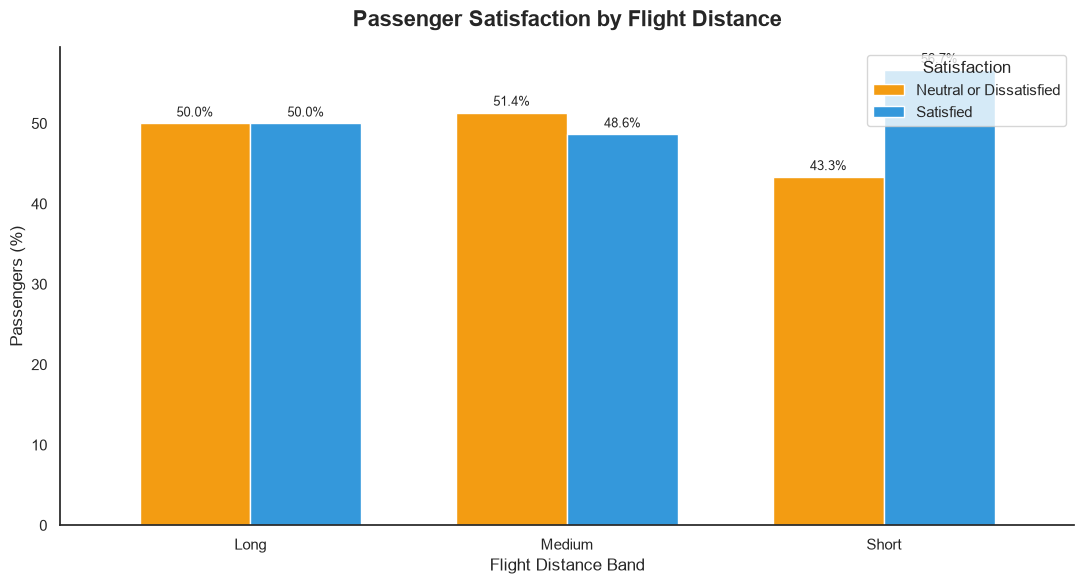

In [25]:
distance_satisfaction = pd.crosstab(
    clean_df["Distance Band"],
    clean_df["Satisfaction"],
    normalize="index"
) * 100

distance_satisfaction = distance_satisfaction.reindex(
    columns=["Neutral or Dissatisfied", "Satisfied"],
    fill_value=0
)

ax = distance_satisfaction.plot(
    kind="bar",
    figsize=(11, 6),
    color=[satisfaction_colors[c] for c in distance_satisfaction.columns],
    edgecolor="white",
    width=0.7
)

plt.title("Passenger Satisfaction by Flight Distance",
          fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Flight Distance Band", fontsize=12)
plt.ylabel("Passengers (%)", fontsize=12)
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

plt.grid(False)
sns.despine()
plt.legend(title="Satisfaction")
plt.tight_layout()
plt.show()

In [26]:
#Airline Service Rating Analysis

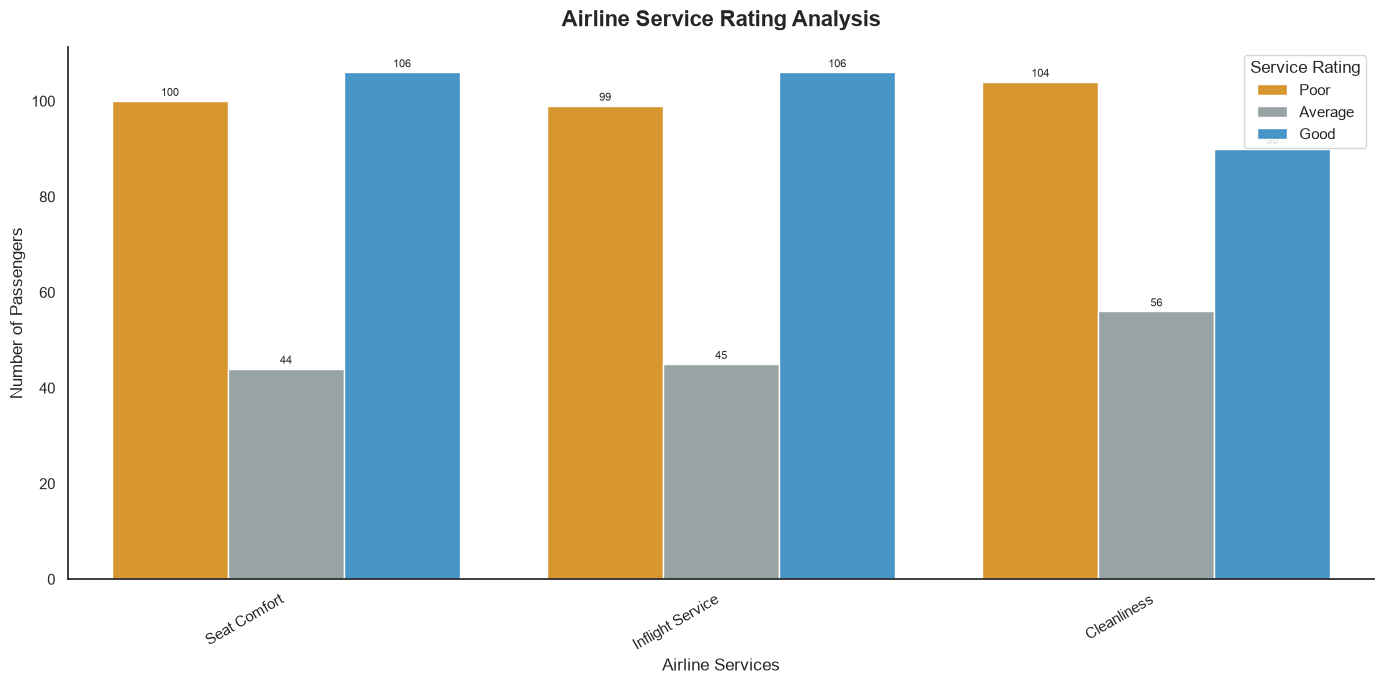

In [27]:
rating_data = clean_df[rating_columns].melt(
    var_name="Service",
    value_name="Rating"
)

plt.figure(figsize=(14, 7))

ax = sns.countplot(
    data=rating_data,
    x="Service",
    hue="Rating",
    hue_order=["Poor", "Average", "Good"],
    palette=rating_colors
)

plt.title("Airline Service Rating Analysis",
          fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Airline Services", fontsize=12)
plt.ylabel("Number of Passengers", fontsize=12)
plt.xticks(rotation=30, ha="right")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=2, fontsize=8)

plt.grid(False)
sns.despine()
plt.legend(title="Service Rating")
plt.tight_layout()
plt.show()

In [28]:
#Customer Type Distribution

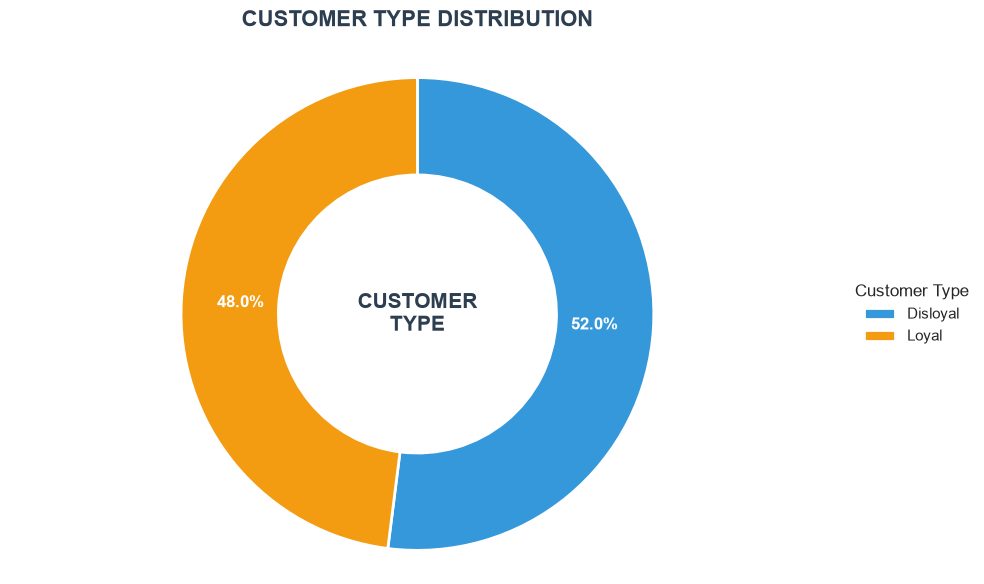

In [29]:
customer_counts = clean_df["Customer Type"].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))

colors = ["#3498DB", "#F39C12"]

wedges, texts, autotexts = ax.pie(
    customer_counts,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=colors,
    pctdistance=0.75,
    radius=0.85,
    wedgeprops=dict(width=0.35, edgecolor="white", linewidth=2),
    textprops=dict(fontsize=12)
)

# Percentage labels
for text in autotexts:
    text.set_fontweight("bold")
    text.set_color("#FFFFFF")
    text.set_fontsize(12)

# Center text
ax.text(
    0, 0,
    "CUSTOMER\nTYPE",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold",
    color="#2C3E50"
)

# Properly arranged legend
ax.legend(
    wedges,
    customer_counts.index,
    title="Customer Type",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=11,
    title_fontsize=12
)

ax.set_title(
    "CUSTOMER TYPE DISTRIBUTION",
    fontsize=16,
    fontweight="bold",
    color="#2C3E50",
    pad=20
)

ax.axis("equal")
plt.tight_layout()
plt.show()

In [30]:
# Business Insights

In [31]:
# 1. Satisfaction by travel class

class_insights = clean_df.groupby("Class")["Satisfaction"].apply(
    lambda x: (x == "Satisfied").mean() * 100
)

print("Satisfaction by Class:")
print(class_insights.round(2).sort_values(ascending=False))

# 2. Satisfaction by customer type

customer_insights = clean_df.groupby("Customer Type")["Satisfaction"].apply(
    lambda x: (x == "Satisfied").mean() * 100
)

print("\nSatisfaction by Customer Type:")
print(customer_insights.round(2))

# 3. Satisfaction by distance band

distance_insights = clean_df.groupby("Distance Band")["Satisfaction"].apply(
    lambda x: (x == "Satisfied").mean() * 100
)

print("\nSatisfaction by Distance Band:")
print(distance_insights.round(2))

# 4. Average departure delay by satisfaction

delay_insights = clean_df.groupby("Satisfaction")["Departure Delay"].mean()

print("\nAverage Departure Delay by Satisfaction:")
print(delay_insights.round(2))

# 5. Service ratings

for col in ["Seat Comfort", "Inflight Service", "Cleanliness"]:
    print(f"\n{col} Rating Distribution (%):")
    print((clean_df[col].value_counts(normalize=True) * 100).round(2))

Satisfaction by Class:
Class
Business    67.50
Eco         44.68
Eco Plus    39.47
Name: Satisfaction, dtype: float64

Satisfaction by Customer Type:
Customer Type
Disloyal    51.54
Loyal       49.17
Name: Satisfaction, dtype: float64

Satisfaction by Distance Band:
Distance Band
Long      50.00
Medium    48.65
Short     56.67
Name: Satisfaction, dtype: float64

Average Departure Delay by Satisfaction:
Satisfaction
Neutral or Dissatisfied    26.81
Satisfied                  25.83
Name: Departure Delay, dtype: float64

Seat Comfort Rating Distribution (%):
Seat Comfort
Good       42.4
Poor       40.0
Average    17.6
Name: proportion, dtype: float64

Inflight Service Rating Distribution (%):
Inflight Service
Good       42.4
Poor       39.6
Average    18.0
Name: proportion, dtype: float64

Cleanliness Rating Distribution (%):
Cleanliness
Poor       41.6
Good       36.0
Average    22.4
Name: proportion, dtype: float64
